# p53 / Mdm2 response to DNA damage

This notebook reproduces the analysis of the p53 / Mdm2 model of the [MaBoSS website](https://maboss.curie.fr).

The model is based on a published model of the p53 response to DNA damage
([Abou-Jaoudé et al., 2009](https://doi.org/10.1016/j.jtbi.2009.02.017)). p53 interacts with Mdm2, which appears
in two forms, cytoplasmic (Mdm2C) and nuclear (Mdm2N). On one hand, p53 upregulates the level of cytoplasmic
Mdm2, which is then transported into the nucleus. On the other hand, nuclear Mdm2 facilitates the degradation
of p53. DNA damage (Dam) participates in the degradation of Mdm2, and p53 inhibits the DNA damage signal by
promoting DNA repair.

p53 has three levels (0, 1 and 2), encoded with two Boolean nodes: `p53` is active when the level of p53 is at
least 1, and `p53_h` when it is 2.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `p53_Mdm2.bnd` and
`p53_Mdm2_runcfg.cfg`, in the same folder as this notebook.

In [1]:
import math
import os
import maboss
import matplotlib.pyplot as plt
from matplotlib.offsetbox import HPacker

# The figures are saved in the "figures" folder
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"savefig.dpi": 150, "savefig.bbox": "tight", "figure.constrained_layout.use": True})

def legend_below():
    """Move the legend of the current figure below the plot, in centered rows of similar widths."""
    figure, legend = plt.gcf(), plt.gca().get_legend()
    handles, labels = legend.legend_handles, [text.get_text() for text in legend.get_texts()]
    legend.remove()
    legend = figure.legend(handles, labels, loc="outside lower center", ncols=1)
    # Matplotlib fills the rows from the left: we rearrange the entries of the legend in centered rows,
    # as few as possible within the width of the plot, and of similar widths
    column = legend._legend_handle_box.get_children()[0]
    entries, column.align = column.get_children(), "center"
    sep = legend.columnspacing * legend.prop.get_size_in_points() * figure.dpi / 72
    widths = [entry.get_bbox(figure.canvas.get_renderer()).width + sep for entry in entries]
    max_width = 0.8 * figure.get_figwidth() * figure.dpi
    for n_rows in range(math.ceil(sum(widths) / max_width), len(entries) + 1):
        rows, row_widths = [[]], [0]
        for entry, width in zip(entries, widths):
            if rows[-1] and row_widths[-1] + width / 2 > sum(widths) / n_rows:
                rows.append([])
                row_widths.append(0)
            rows[-1].append(entry)
            row_widths[-1] += width
        if max(row_widths) <= max_width:
            break
    column._children = [HPacker(sep=sep, align="baseline", children=row) for row in rows]

## Simulation

The initial condition is [p53 Mdm2C Mdm2N Dam] = [0 \* 1 1]: DNA damage is present, nuclear Mdm2 is active,
and p53 is inactive.

In [2]:
sim = maboss.load("p53_Mdm2.bnd", "p53_Mdm2_runcfg.cfg")
result = sim.run()

## Node probabilities

The probability of `p53` is the probability that the level of p53 is at least 1, and the probability of `p53_h`
the probability that it is 2.

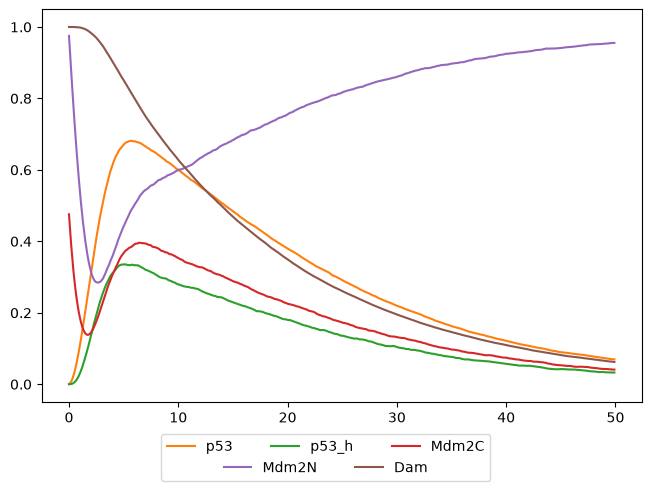

In [3]:
result.plot_node_trajectory()
legend_below()
plt.savefig("figures/p53_nodes.png")

## Entropies

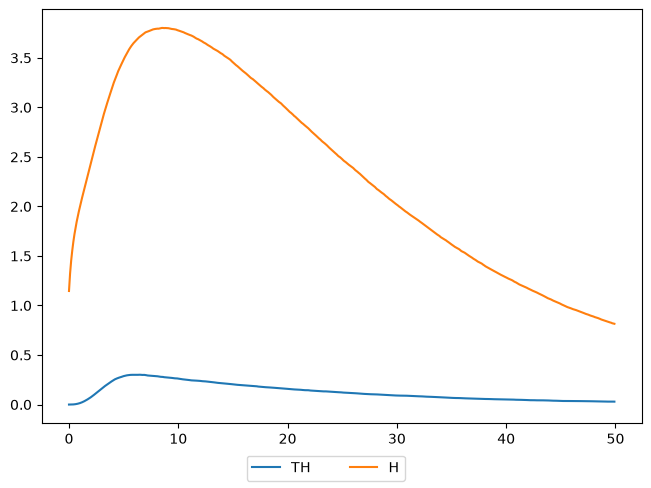

In [4]:
result.plot_entropy_trajectory()
legend_below()
plt.savefig("figures/p53_entropies.png")